<a href="https://colab.research.google.com/github/Abdoulaye279/Quantum-Computing/blob/main/01_ideal_gate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 - Ideal Cirac-Zoller gate

Pulse sequence of Table 1 in Schmidt-Kaler et al., Nature 422, 408 (2003): map ion 1 onto the bus, Ramsey pi/2 on ion 2, composite phase gate (4 blue sideband pulses), Ramsey pi/2, map back. Qubits in S (0) and D (1), bus truncated at 8 phonons. The physics is in `cirac_zoller.py`.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Quantum-Computing
    %cd Quantum-Computing
except ImportError:
    pass

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cirac_zoller import *
plt.style.use("quant.mplstyle")

labels = ["SS", "SD", "DS", "DD"]

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]


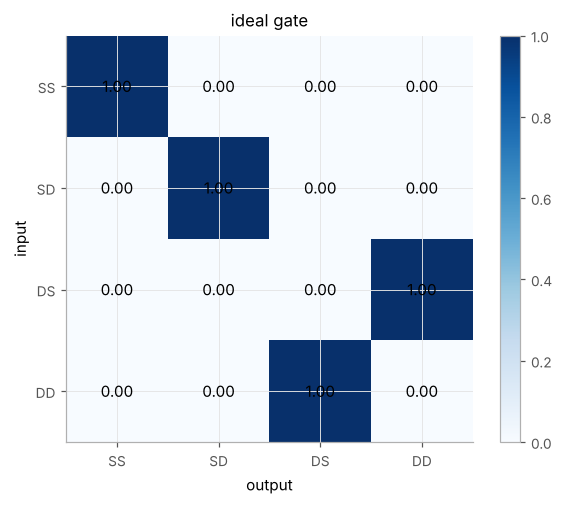

In [3]:
T = truth_table(shots=1)
print(np.round(T, 3))
plt.imshow(T, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(4), labels); plt.yticks(range(4), labels)
plt.xlabel("output"); plt.ylabel("input")
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{T[i, j]:.2f}", ha="center", va="center")
plt.title("ideal gate"); plt.colorbar(); plt.show()
# a CNOT in populations: SS->SS, SD->SD, DS->DD, DD->DS

In [4]:
CY = np.eye(4, dtype=complex)
CY[2:, 2:] = [[0, -1j], [1j, 0]]
print("full operator = -CY:", np.allclose(eff_unitary(gate_amp(0.0)), -CY))
# looking at amplitudes and not only populations, the sequence is -CY (ion 1 control, ion 2 target)
# = a CNOT up to an S / S-dagger on the target. the paper only shows populations so this can't be seen there

full operator = -CY: True


Bell fidelity 1.0


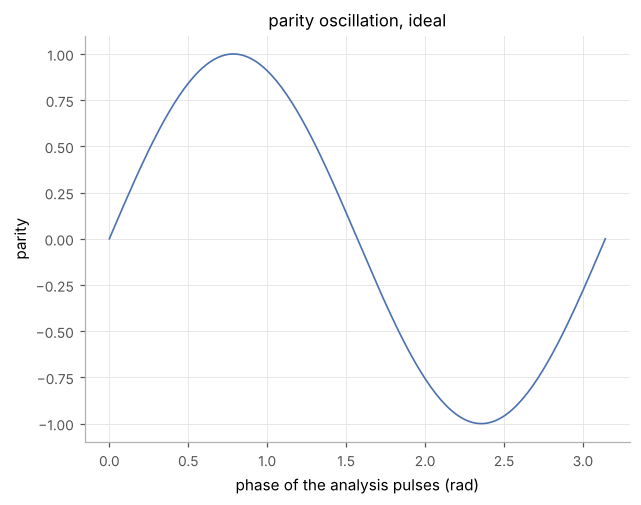

In [5]:
rho = run(bell_input, shots=1)
print("Bell fidelity", round(bell_fidelity(rho), 4))
phis = np.linspace(0, np.pi, 200)
plt.plot(phis, parity_curve(rho, phis))
plt.xlabel("phase of the analysis pulses (rad)"); plt.ylabel("parity"); plt.title("parity oscillation, ideal")
plt.show()
# (|S>+|D>)|S> gives a Bell state, parity oscillates as cos(2 phi) -> entangled (a product state would give cos phi)